In [1]:
import gc
import joblib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer, r2_score, root_mean_squared_error

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance
from sklearn.inspection import PartialDependenceDisplay

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

from sklearn.neural_network import MLPRegressor

<h2>Read-in Data</h2>

In [2]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32'
}

In [4]:
campd_ny = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_ny["Date"] = pd.to_datetime(campd_ny["Date"])
campd_ny["datetime"] = pd.to_datetime(campd_ny["datetime"])

<h2>Preprocessing Methods</h2>

In [ ]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # add the previous year temporarily to get lags for the first year
    df = pd.concat([df, previous_year_df])

    df = df.set_index("datetime")

    df = df.sort_index()
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # apply the lag feature function to each group
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime({
    'year': df["Date"].dt.year,
    'month': df["Date"].dt.month,
    'day': df["Date"].dt.day,
    'hour': df["Hour"]
    })


    return df


In [ ]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # Split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # Concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_ny, ny_code_cols = preprocess_program_codes(campd_ny)
# ny_code_cols

<h2>Model-independent Preprocessing</h2>

- create time-lags
- manually OHE program codes
- downsample the non-operating rows by 90%
- remove rows where NOx was not fully measured

In [ ]:
# read in previous year to get according lags
campd_ny_2018 = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2018-ny.csv", dtype=campd_type_dict, parse_dates=["Date"])
campd_ny_2018 = campd_ny_2018[["Facility ID", "Unit ID", "Date", "Hour", "CO2 Mass (short tons)"]]
campd_ny_2018["datetime"] = pd.to_datetime({
    'year': campd_ny_2018["Date"].dt.year,
    'month': campd_ny_2018["Date"].dt.month,
    'day': campd_ny_2018["Date"].dt.day,
    'hour': campd_ny_2018["Hour"]
    })
campd_ny_2018["CO2 Mass (short tons)"] = campd_ny_2018["CO2 Mass (short tons)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_ny, campd_ny_2018, "CO2 Mass (short tons)")

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_with_CO2_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_with_CO2_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [ ]:
# manually one-hot encode program codes
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded.csv", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded.csv", dtype=campd_type_dict)

In [ ]:
# Randomly remove a fraction of rows where Operating Time is 0.
def downsample_zero_operating_time(df, frac_to_remove=0.9, random_state=42):
    # create dfs for those with and without operating time
    zero_op = df[df["Operating Time"] == 0]
    non_zero_op = df[df["Operating Time"] != 0]

    # remove sample of rows
    drop_sample = zero_op.sample(frac=frac_to_remove, random_state=random_state)
    kept_zero_op = zero_op.drop(index=drop_sample.index)
    df_downsampled = pd.concat([non_zero_op, kept_zero_op]).sort_index()

    return df_downsampled


In [ ]:
# Downsample 90% of the nonOperating data (should be fine since xgb does not require continuity unlike e. g. LSTM)
campd_df = downsample_zero_operating_time(campd_df)

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled.csv", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled.csv", dtype=campd_type_dict)

In [ ]:
campd_df["CO2 Mass Measure Indicator"].value_counts()

CO2 Mass Measure Indicator
Measured                   2251406
Nothing                    1162797
Measured and Substitute      76386
LME                          72482
Substitute                     427
Name: count, dtype: Int64

In [ ]:
campd_df = campd_df[(campd_df["CO2 Mass Measure Indicator"] == "Measured") | (campd_df["CO2 Mass Measure Indicator"] == "Nothing")]
campd_df["CO2 Mass Measure Indicator"].value_counts()

CO2 Mass Measure Indicator
Measured    2251406
Nothing     1162797
Name: count, dtype: Int64

In [ ]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", index=False, compression="gzip")

In [3]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [4]:
campd_df.shape

(3414203, 80)

<h2>Regression Models</h2>

- for each model type, we preprocess data appropriately and evaluate models with default parameters using 2019-2023 training data and 2024 as the test data
-> prepare models for xAI analysis

<h3>Linear Regression</h3>

- build ridge regression models without and with lags
- LR cannot handle nulls inherently -> remove nan cols with >50% (summer/winter capacity + min load) and filter out any remaining rows with null values

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.csv", dtype=campd_type_dict)

In [11]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] #+ lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

In [12]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]


# remove nan cols with excessive number of nan vals otherwise removing respective nan rows

Gross Load (MW)              6.013790
Latitude                    10.389658
Longitude                   10.389658
Nameplate Capacity (MWe)    10.389658
hourly_capacity_factor       6.989830
hourly_ramping_factor       16.404619
Summer Capacity (MW)        58.477659
Winter Capacity (MW)        58.477659
Minimum Load (MW)           58.477659
Temperature (F)              1.702535
dtype: float64

In [13]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3414203, 80), New shape: (2822490, 80)
Change in total rows: -591713


In [26]:
# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] #+ lag_cols

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (CO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

<h4>No Lags</h4>

R^2 Score: 0.9978
Mean Squared Error (MSE): 7.0776
Root Mean Squared Error (RMSE): 2.6604
Normalized RMSE (by std): 0.0471


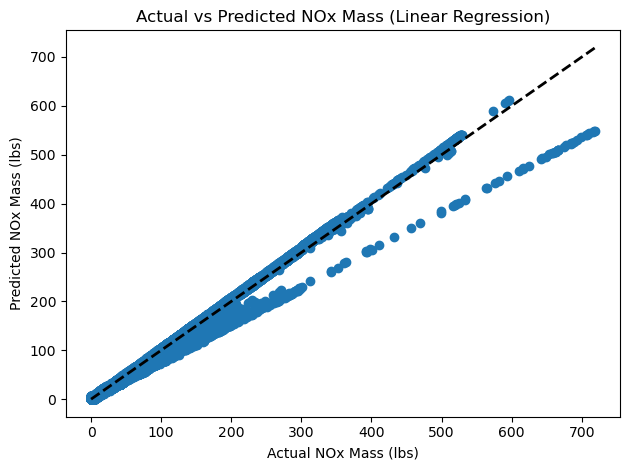

In [25]:
# default model (no lags, no unmeasured, with temps)

# Ridge Regression

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h4>With Lags</h4>

In [ ]:
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any remaining NaN values (lags)
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

R^2 Score: 0.9973
Mean Squared Error (MSE): 8.5019
Root Mean Squared Error (RMSE): 2.9158
Normalized RMSE (by std): 0.0516


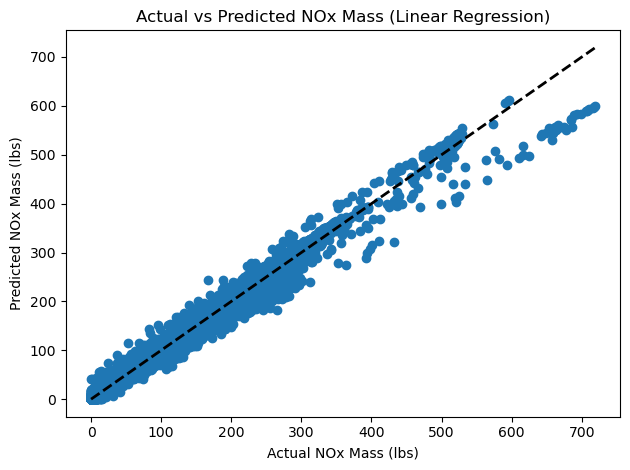

In [29]:
# default model (with lags, no unmeasured, with temps)

# Ridge Regression

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h3>Random Forest</h3>

- build both RF models using sklearn default parameters without and with lags
- this version of RF handles null values inherently so we do not need to impute/remove them
- to keep training computationally feasible, we downsample the training data to 20%

In [ ]:
# default params are:
# n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, 
# min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
# max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
#  n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, 
# ccp_alpha=0.0, max_samples=None, monotonic_cst=None

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [ ]:

df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (CO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
# rf struggles with large datasets, so we downsample the training data to 20%
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_sampled = y_train.loc[y_train.index.isin(sample_indices)]

In [7]:
X_sampled.shape

(572927, 115)

In [8]:
# still takes approx. 3 mins to compute

rf_model_no_lags = RandomForestRegressor(random_state=42, n_jobs=-1) # max_depth=5 without max depth it takes very long

# Train Random Forest model with default parameters
rf_model_no_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [9]:
joblib.dump(rf_model_no_lags, "NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

['NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json']

In [57]:
rf_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

R^2 Score: 0.9993
Mean Squared Error (MSE): 2.0843
Root Mean Squared Error (RMSE): 1.4437
Normalized RMSE (by std): 0.0260


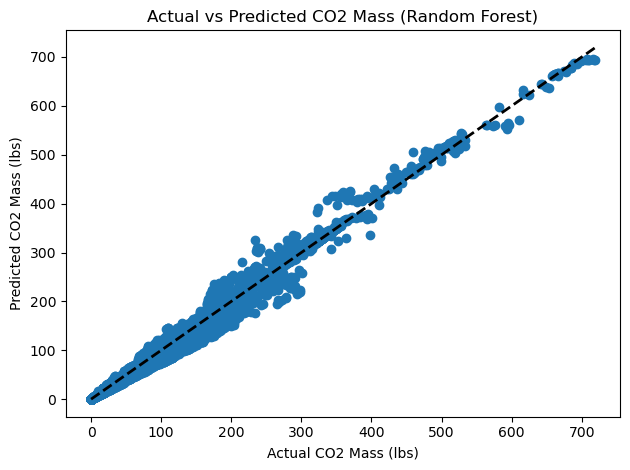

In [10]:
# default model (no lags, no unmeasured data, with temps)

y_pred = rf_model_no_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

In [ ]:
# even with downsampling takes approx. 4 mins to compute

rf_model_with_lags = RandomForestRegressor(random_state=42, n_jobs=-1) # max_depth=5 without max depth it takes very long

rf_model_with_lags.fit(X_sampled, y_sampled.values.ravel())

joblib.dump(rf_model_with_lags, "NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_with_lags_no_unmeasured_with_temps.json")

['NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_with_lags_no_unmeasured_with_temps.json']

In [ ]:
rf_model_with_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_with_lags_with_unmeasured_with_temps.json")

R^2 Score: 0.9996
Mean Squared Error (MSE): 1.2924
Root Mean Squared Error (RMSE): 1.1368
Normalized RMSE (by std): 0.0205


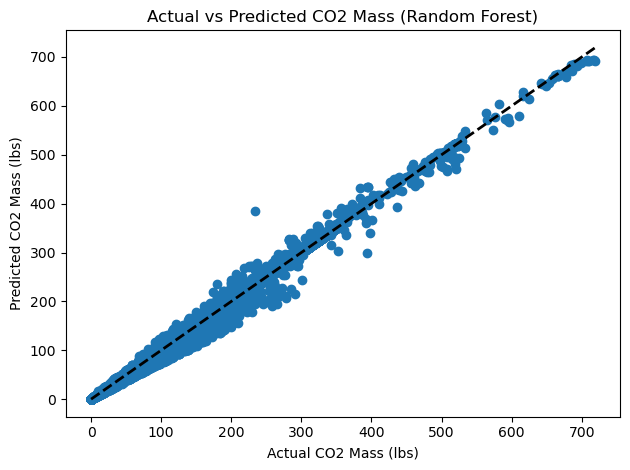

In [ ]:
# default model (with lags, no unmeasured data, with temps)

y_pred = rf_model_with_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

<h3>XGBoost</h3>

<h6>Preprocessing</h6>

In [4]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", index=False)

In [ ]:
# https://www.ecfr.gov/current/title-40/chapter-I/subchapter-C/part-75/appendix-Appendix%20G%20to%20Part%2075
# Eq. G-4

# eq. G-4 is only meant for gas- and oil-fired units
natural_gas = ["Pipeline Natural Gas", 
                    "Natural Gas"]

oil = ["Diesel Oil","Residual Oil", "Other Oil"]


campd_df.loc[campd_df["Primary Fuel Type"].isin(natural_gas), "Calc CO2 Mass (tons)"] = (44 * 1040 * campd_df["Heat Input (mmBtu)"] * (1 / 385)) / 2000

campd_df.loc[campd_df["Primary Fuel Type"].isin(oil), "Calc CO2 Mass (tons)"] = (44 * 1420 * campd_df["Heat Input (mmBtu)"] * (1 / 385)) / 2000


In [ ]:
# features
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)',
                 "Calc CO2 Mass (tons)"] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (CO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_factor',
                                  'Summer Capacity (MW)',
                                  'Winter Capacity (MW)', 'Minimum Load (MW)',
                                  'Year', 'Temperature (F)',
                                  'Calc CO2 emission rate (tons)']),
                                ('encoded', 'passthrough',
                                 ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3',
                                  'CSSO2G1', 'MATS', 'Missing', 'NSPS4T',
                                  'RGGI', 'SIPNOX'])])

In [ ]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_train.csv", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_test.csv", index=False)
y_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/y_train.csv", index=False)
y_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/y_test.csv", index=False)

In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_train.csv", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_test.csv", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/y_train.csv")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/y_test.csv")

In [19]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_train_processed.csv", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_test_processed.csv", index=False)

In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_train_processed.csv", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/CO2/X_test_processed.csv", dtype=campd_type_dict)

In [20]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [26]:
dtrain.save_binary("NY/Hourly/Concatted File/Modeling/XGB/CO2/dtrain_ny_full_2019_2023.buffer")
dtest.save_binary("NY/Hourly/Concatted File/Modeling/XGB/CO2/dtest_ny_full_2024.buffer")

In [13]:
dtrain = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/CO2/dtrain_ny_full_2019_2023.buffer")
dtest = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/CO2/dtest_ny_full_2024.buffer")

<h6>Train All, Test Year 2024</h6>

In [ ]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
}

R^2 Score: 0.9992
Mean Squared Error (MSE): 2.3579
Root Mean Squared Error (RMSE): 1.5355
Normalized RMSE (by std): 0.0277


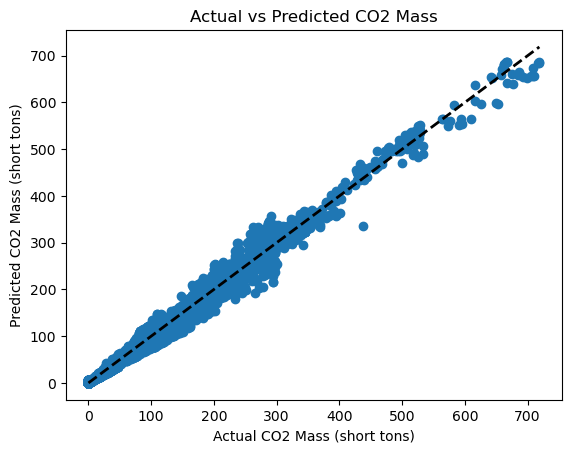

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

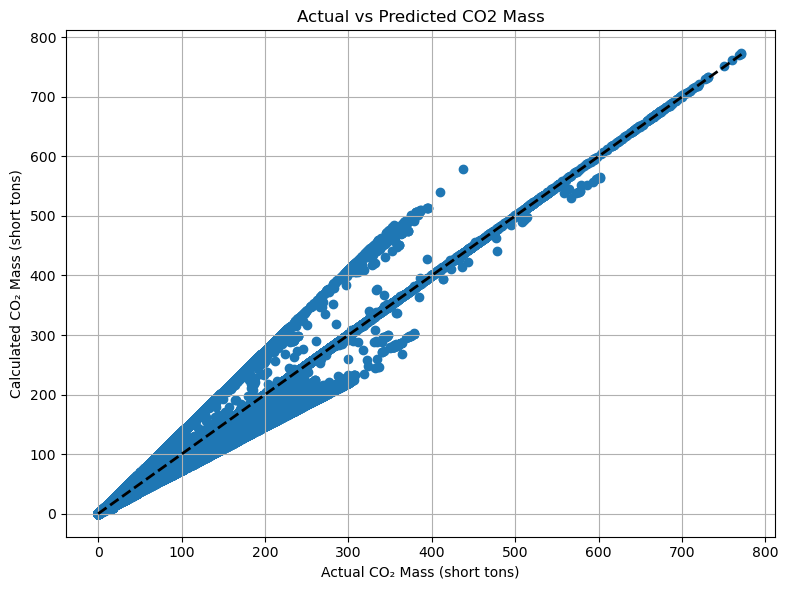

R² Score: 0.9956
Mean Squared Error (MSE): 12.6540
Root Mean Squared Error (RMSE): 3.5572
Normalized RMSE (by std): 0.0662


In [ ]:
# calc co2 alone (formula from Part 75 Appendix G)
# only gas- and oil-fired units

# Define actual and predicted values
y_actual = campd_df["CO2 Mass (short tons)"]
y_predicted = campd_df["Calc CO2 Mass (tons)"]

# Drop rows with NaNs in either column
valid_mask = y_actual.notna() & y_predicted.notna()
y_actual_clean = y_actual[valid_mask]
y_predicted_clean = y_predicted[valid_mask]

# Scatter plot: Actual vs Predicted CO2 Mass
plt.figure(figsize=(8, 6))
plt.scatter(y_actual_clean, y_predicted_clean)
plt.xlabel("Actual CO₂ Mass (short tons)")
plt.ylabel("Calculated CO₂ Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")

# 1:1 reference line
min_val = min(y_actual_clean.min(), y_predicted_clean.min())
max_val = max(y_actual_clean.max(), y_predicted_clean.max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2)

plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluate performance
r2 = r2_score(y_actual_clean, y_predicted_clean)
mse = mean_squared_error(y_actual_clean, y_predicted_clean)
rmse = np.sqrt(mse)
nrmse = rmse / np.std(y_actual_clean)

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Normalized RMSE (by std): {nrmse:.4f}")

# some errors are introduced due to a missing flag of which fuel type is being used
# some units may switch between gas and oil

R^2 Score: 0.9993
Mean Squared Error (MSE): 2.1616
Root Mean Squared Error (RMSE): 1.4703
Normalized RMSE (by std): 0.0265


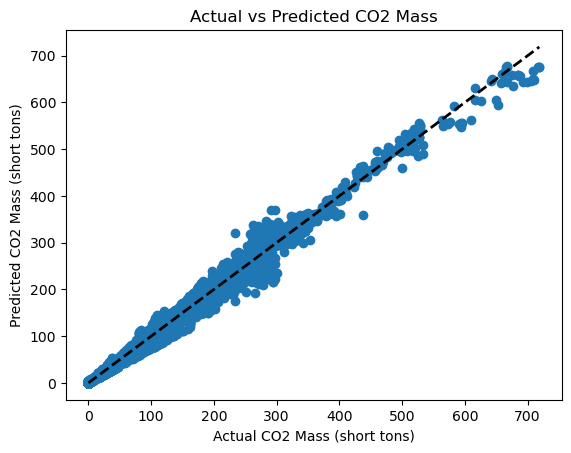

In [ ]:
# model with default parameters (no lags, no unmeasured data, with calc co2 as a feature)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9995
Mean Squared Error (MSE): 1.4329
Root Mean Squared Error (RMSE): 1.1970
Normalized RMSE (by std): 0.0216


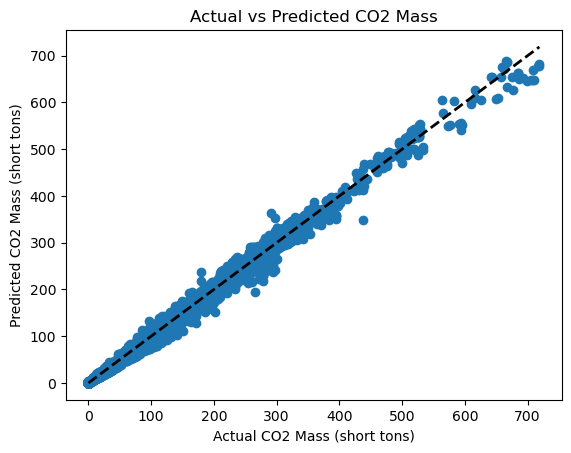

In [ ]:
# model with default parameters (with lags, no unmeasured data)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [ ]:
# load saved models

xgb_default_model_with_lags = xgb.Booster()
xgb_default_model_with_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured.json")

rf_default_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

rf_default_model_with_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/CO2/Trained Models/rf_default_model_ny_with_lags_no_unmeasured_with_temps.json")

<h3>RF (model-specific)</h3>

- Mean Decrease in Impurity (MDI) for RF without and with lags

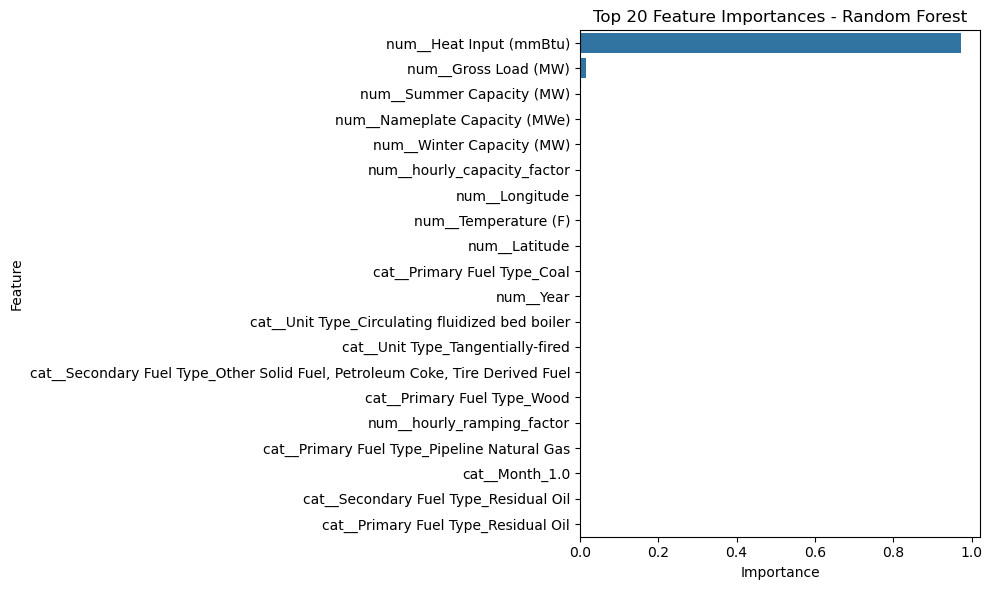

In [78]:
# for default rf model no lags, no unmeasured data, with temps

importances = rf_default_model_no_lags.feature_importances_

# Create a DataFrame for better handling
feat_imp_df = pd.DataFrame({
    'Feature': X_sampled.columns,
    'Importance': importances
})

# Sort by importance
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


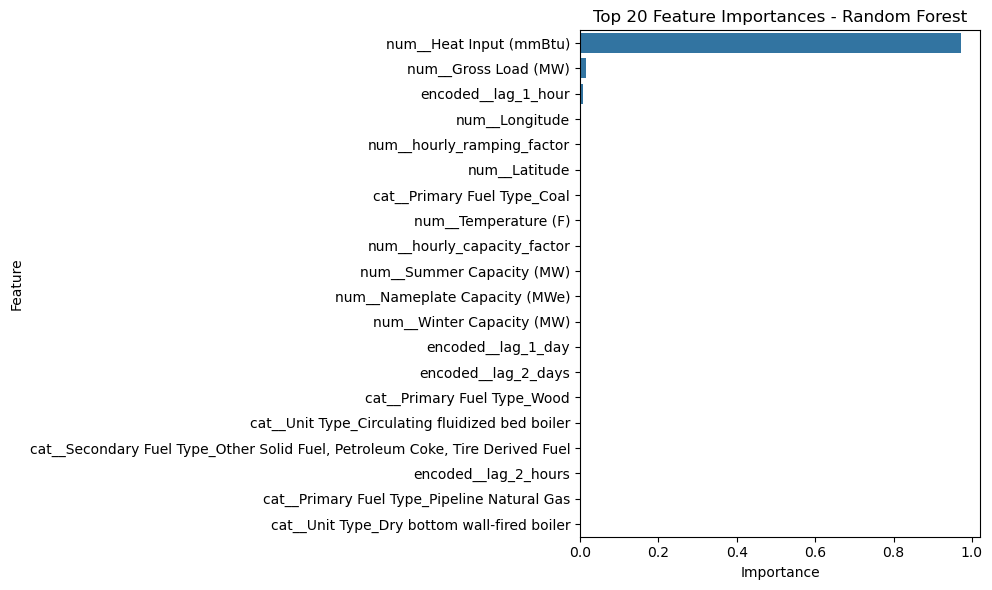

In [81]:
# for default rf model with lags, no unmeasured data, with temps

importances = rf_default_model_with_lags.feature_importances_

# Create a DataFrame for better handling
feat_imp_df = pd.DataFrame({
    'Feature': X_sampled.columns,
    'Importance': importances
})

# Sort by importance
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


<h3>XGB (model-specific)</h3>

- Weight, gain, and cover for XGB with and without lags

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

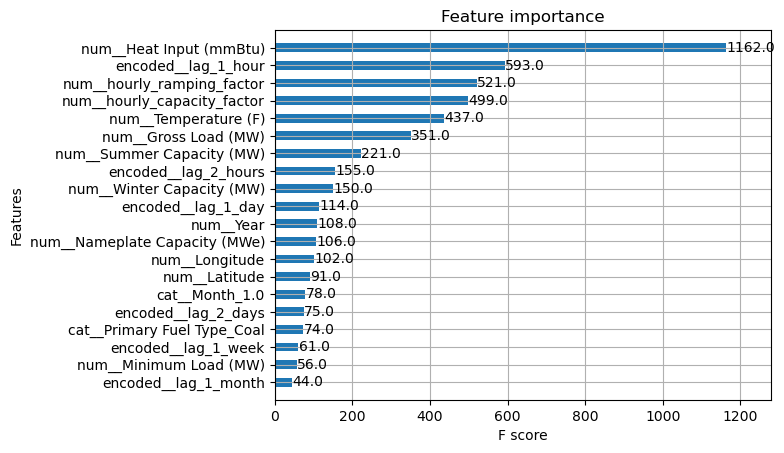

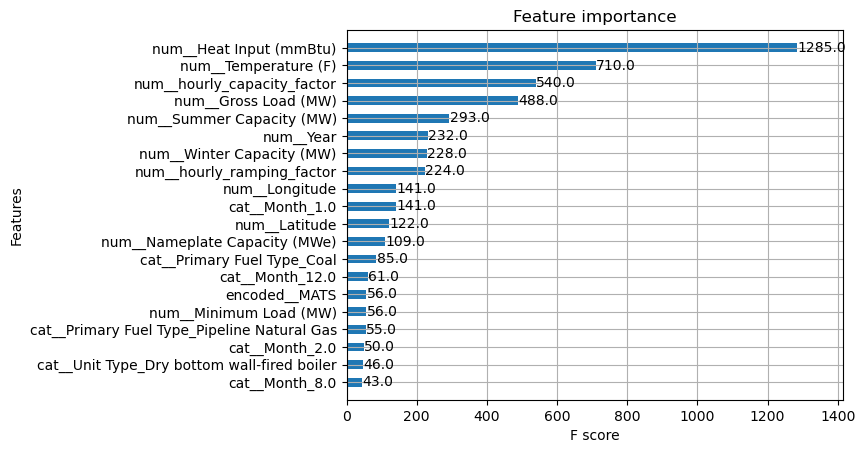

In [82]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

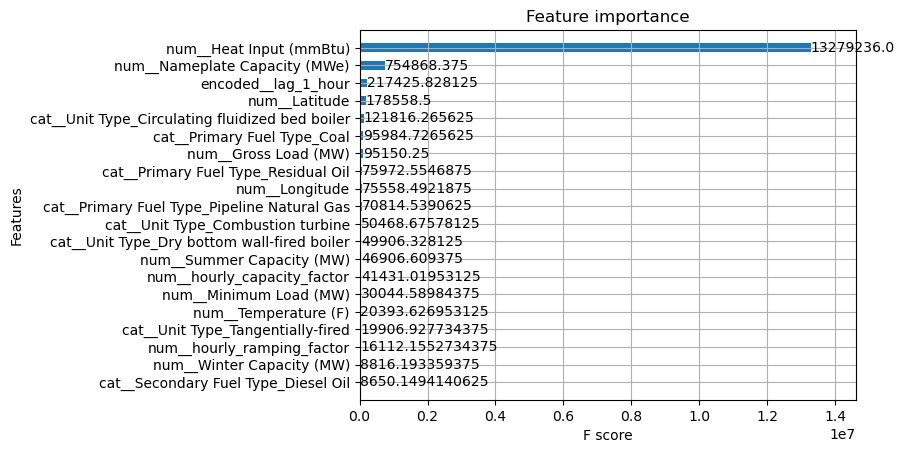

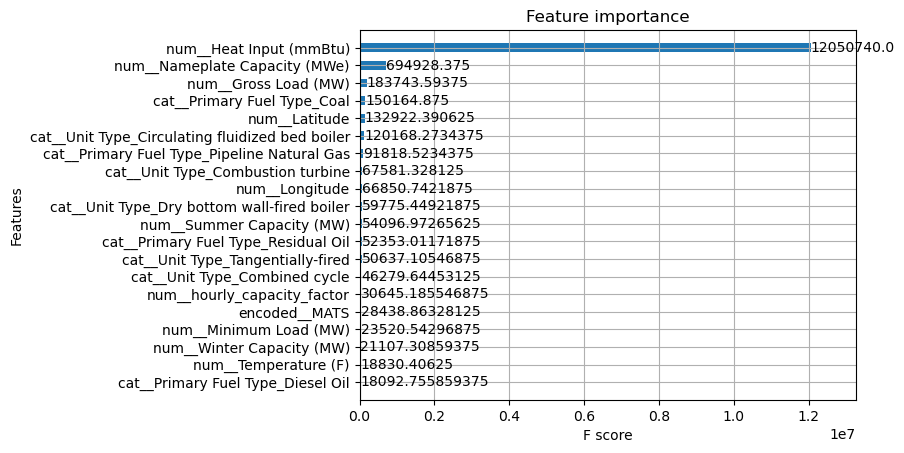

In [83]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

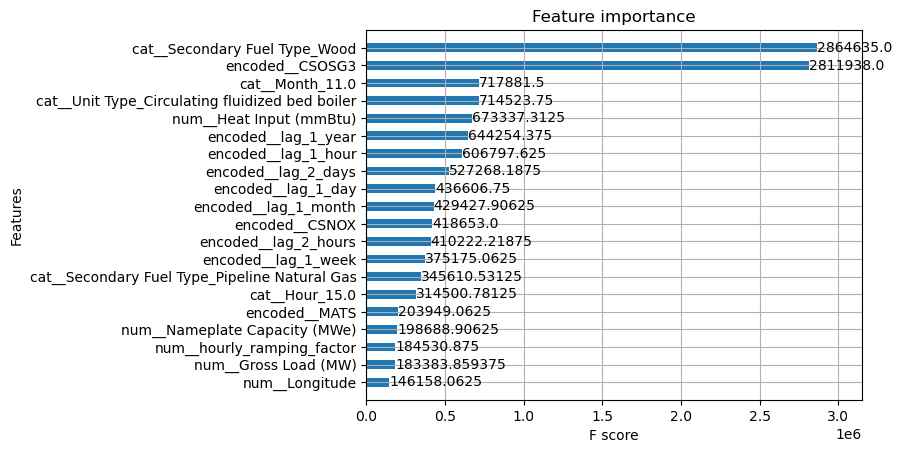

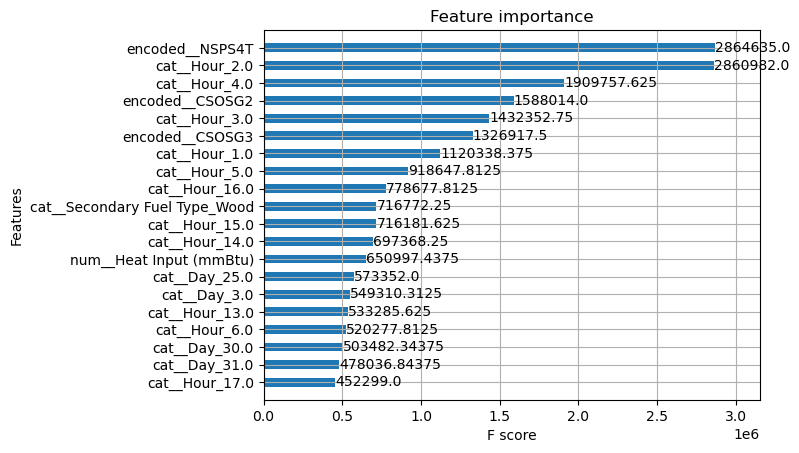

In [84]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Permutation Importance</h3>

- compute and display permutation importance without lags

In [85]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_lags

In [89]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_mean_squared_error')

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)


,feature,importance_mean,importance_std
93,num__Heat Input (mmBtu),6828.015463,8.444190
94,num__Latitude,58.285907,0.790893
96,num__Nameplate Capacity (MWe),32.315474,0.742057
92,num__Gross Load (MW),24.940495,0.135669
97,num__hourly_capacity_factor,21.247558,0.499510
...,...,...,...
9,cat__Month_10.0,-0.009148,0.001705
5,cat__Month_6.0,-0.033172,0.004364
62,cat__Day_27.0,-0.039583,0.006470
57,cat__Day_22.0,-0.046622,0.000969


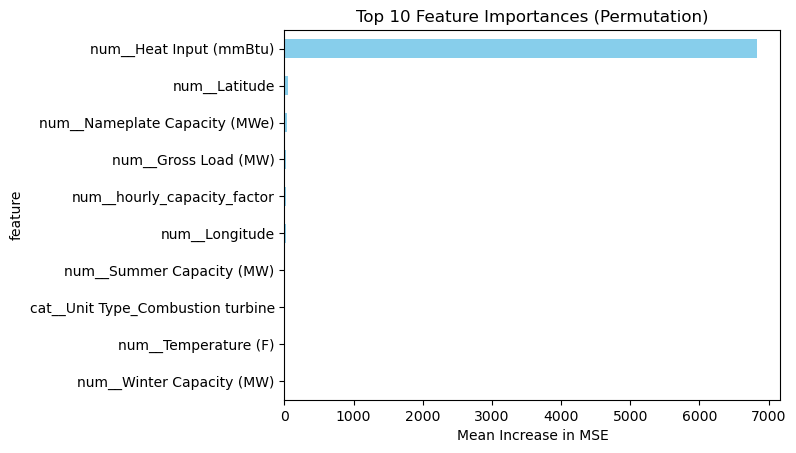

In [90]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

<h5>No Lags</h5>

In [91]:
explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [92]:
shap_values = explainer(X_test, approximate=False)

In [93]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured.pkl")

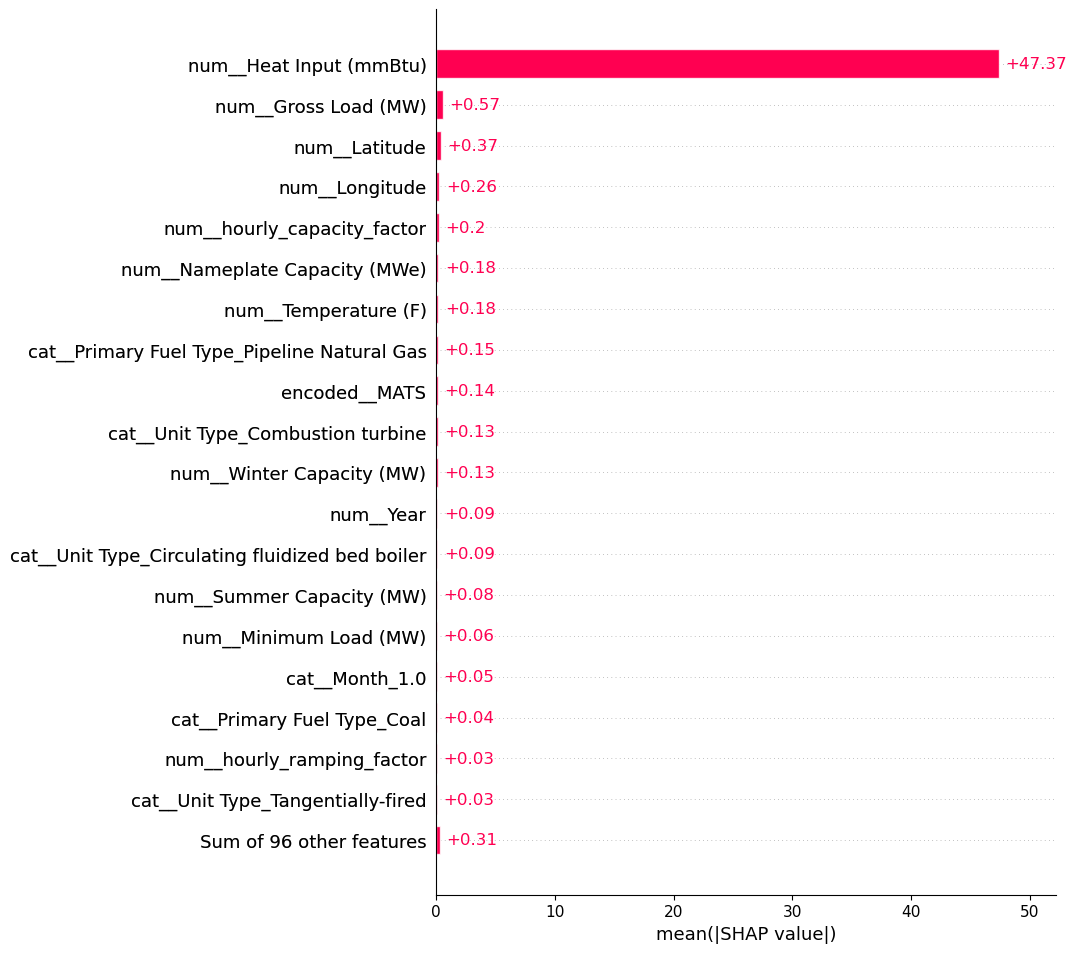

In [94]:
shap.plots.bar(shap_values, max_display=20)

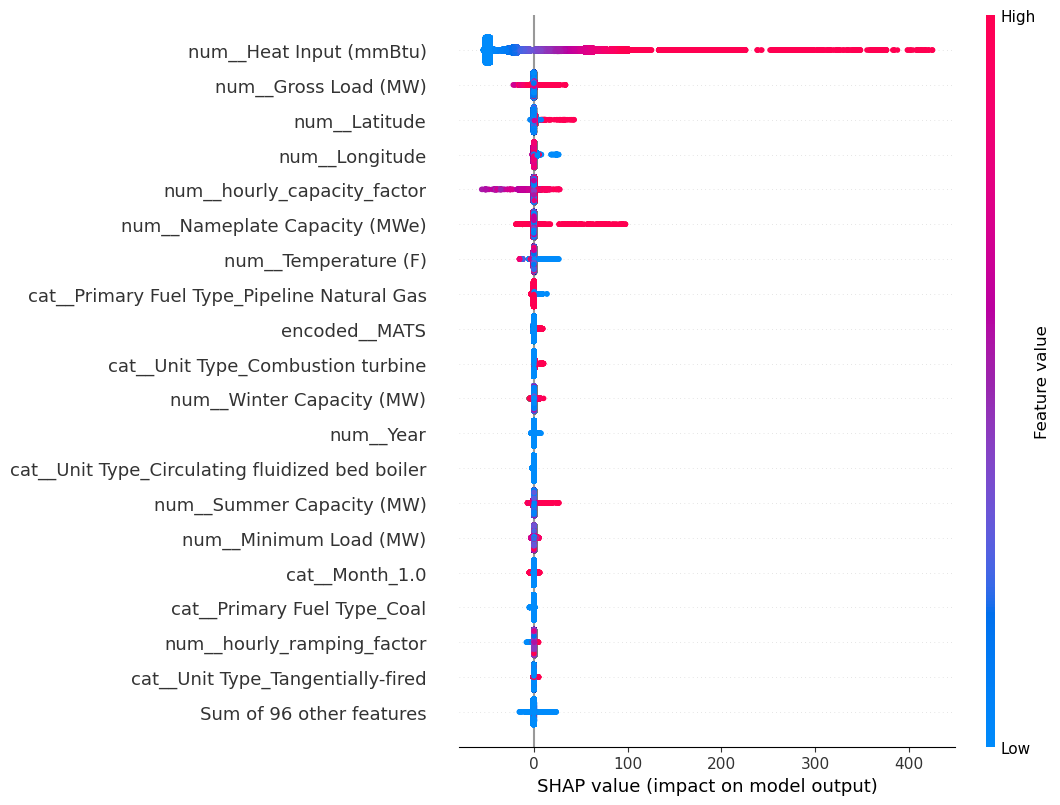

In [95]:
shap.plots.beeswarm(shap_values, max_display=20)